# TP: Machine Learning

## TP2: Classification (4h) 

In machine learning, classification is related to supervised learning approaches in which the algorithm fits from an annotated set of data. This learning phase is followed by a validation phase to evaluate the classification model through several metrics. Once the model is correctly validated, a generalization phase is used to classify new data.

The given dataset was produced by the World Health Organization. It pooled the evolution of 20 features for 15 years and among numerous countries. One of the goals of this TP2 is to visualize feature space and try to predict the development of countries.

**Objectives:**
- Visualize the feature space
- Discuss the feasibility of feature space separation
- Normalize the datasets
- Train a K-NN, a decision tree, a random forest and a SVM
- Visualize the decision boundary for each method
- Create a test dataset
- Compute AUC scores on a evaluation dataset
- Tune hyperparameters
- Visualize the modification of decision boundary for each tuning
- Discuss the limits of the four implementations

This TP has different **checkpoints**. Please call your teacher at the end of each checkpoint to validate your work. Any non validated work won't be taken into account in the notation


## STEP 1: Feature space visualization

You will work on the WHO dataset in the year 2000. This first step consists of choosing two features to perform a classification.

**TO DO 1.1**

If you are using jupyter-notebook, execute the following cell :

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors
import numpy as np

df = pd.read_csv("data/Life_Expectancy_Data.csv")
df = df.dropna()
df.info()

df1 = df[(df.Year == 2000)]

<class 'pandas.core.frame.DataFrame'>
Index: 1649 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          1649 non-null   object 
 1   Year                             1649 non-null   int64  
 2   Status                           1649 non-null   object 
 3   Life_expectancy                  1649 non-null   float64
 4   Adult_mortality                  1649 non-null   float64
 5   Infant_deaths                    1649 non-null   int64  
 6   Alcohol                          1649 non-null   float64
 7   Percentage_expenditure           1649 non-null   float64
 8   Hepatitis_B                      1649 non-null   float64
 9   Measles                          1649 non-null   int64  
 10  BMI                              1649 non-null   float64
 11  Under-five_deaths                1649 non-null   int64  
 12  Polio                    

C:\Users\Fatima\AppData\Local\Temp\ipykernel_25636\2760979751.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])


<module 'matplotlib.pyplot' from 'c:\\Users\\Fatima\\AppData\\Local\\Programs\\Python\\Python310\\lib\\site-packages\\matplotlib\\pyplot.py'>

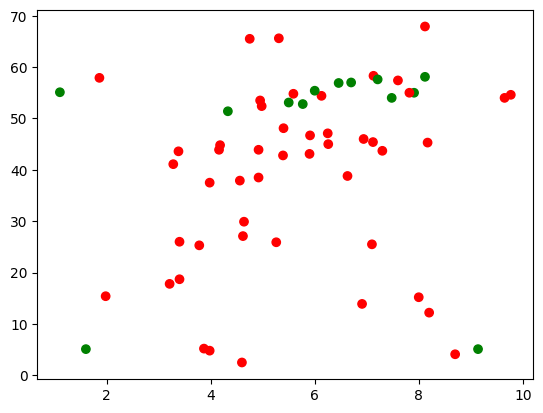

In [4]:
df_X = df1[['Total_expenditure', 'BMI']]
df_Status = df1[['Status']]

df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])

np1 = df_X.to_numpy()
plt.scatter(np1[:,0], np1[:,1], c=np.squeeze(df_Y.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))
plt

**QUESTION 1**

Why was the label status binarized?

Is this feature space easily separable? Justify your response

**Answer**

1. The label status was binarized becase the problem is dealing with 2 classes (developing-0 and developed-1). Allow the classification algorithm to work with target variable.

2. from the plot, theres a lot of overlapping between the classes in the featue space, not linearly seperable. 

**TO CODE 1.2**

Plot Total expenditure against Schooling

C:\Users\Fatima\AppData\Local\Temp\ipykernel_25636\2425672158.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])


<module 'matplotlib.pyplot' from 'c:\\Users\\Fatima\\AppData\\Local\\Programs\\Python\\Python310\\lib\\site-packages\\matplotlib\\pyplot.py'>

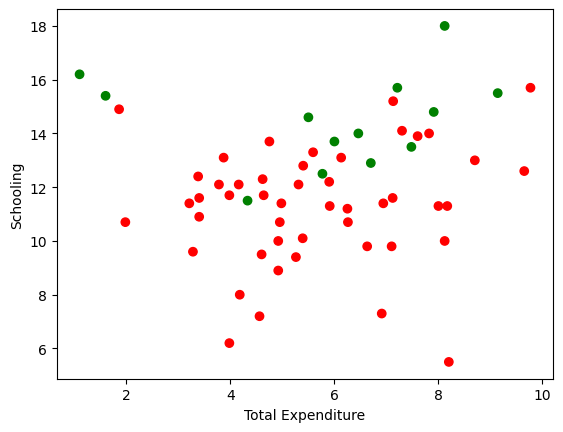

In [5]:
df_X= df1[['Total_expenditure','Schooling']]
df_Status = df1[['Status']]
df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])

plt.scatter(df_X['Total_expenditure'], df_X['Schooling'], c=np.squeeze(df_Y.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))

plt.xlabel('Total Expenditure')
plt.ylabel('Schooling')
plt


**TO CODE 1.3**

Plot Life Expectancy against Schooling

<module 'matplotlib.pyplot' from 'c:\\Users\\Fatima\\AppData\\Local\\Programs\\Python\\Python310\\lib\\site-packages\\matplotlib\\pyplot.py'>

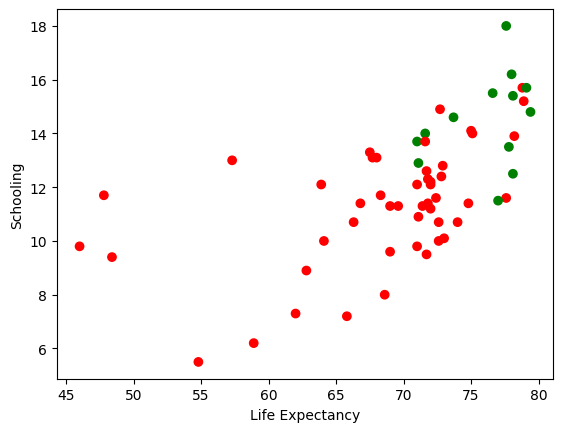

In [6]:
df_X = df1[['Life_expectancy', 'Schooling']]
plt.scatter(df_X['Life_expectancy'], df_X['Schooling'], c=np.squeeze(df_Y.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))

plt.xlabel('Life Expectancy')
plt.ylabel('Schooling')
plt

**QUESTION 2**

What would be the best features to use? Justify your response

Use those features as df_X.

**ANSWER**

Life Expectancy and  Schooling since the plots of the two featues show somehow a clearer seperation between the 2 classes than the others , even though overlapping still shows (non linearly seperable)

## Checkpoint : 1
Call your teacher to validate the first step of the TP

## STEP 2: Dataset normalization

To classify, the values in the learning dataset must be normalized (aka between 0 and 1). This normalization can be performed through various ways.

**TO CODE 2.1**

Normalize df_X. This normalization should perfectly frame the data (aka the minimum and the maximum values of each feature should be respectively 0 and 1).

In [7]:
df_X_norm = (df_X - df_X.min()) / (df_X.max() - df_X.min())

np_X_norm = df_X_norm.to_numpy()
print(df_X_norm.min().values, df_X_norm.max().values)

df_X = df1[['Life_expectancy', 'Schooling']]
df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])

np_X = df_X.to_numpy()
np_Y = np.squeeze(df_Y.to_numpy())


[0. 0.] [1. 1.]


C:\Users\Fatima\AppData\Local\Temp\ipykernel_25636\4254253357.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])


**TO DO 2.2**

Each following cell performs a learning step and an AUC scores computation. For each classifier, several parameters have been chosen.

(61, 2)


c:\Users\Fatima\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
c:\Users\Fatima\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


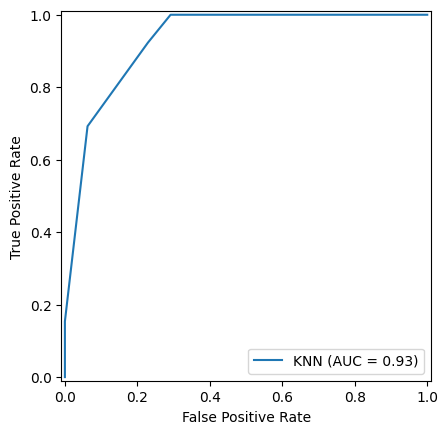

In [20]:
from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier

clf1 = KNeighborsClassifier(n_neighbors=5)
clf1.fit(np_X_norm, np_Y)

np_Y_pred = clf1.predict_proba(df_X_norm)
print(np_Y_pred.shape)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   estimator_name='KNN')
display.plot()
plt.show()

c:\Users\Fatima\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
c:\Users\Fatima\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


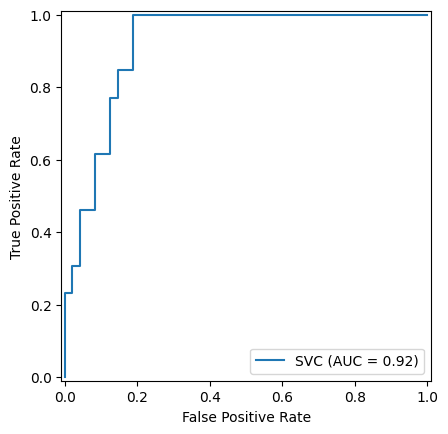

In [9]:
from sklearn.svm import SVC

clf2 = SVC(C=2.0, kernel='linear', probability=True)
clf2.fit(np_X_norm, np_Y)

np_Y_pred = clf2.predict_proba(df_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   estimator_name='SVC')
display.plot()
plt.show()

c:\Users\Fatima\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\Fatima\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


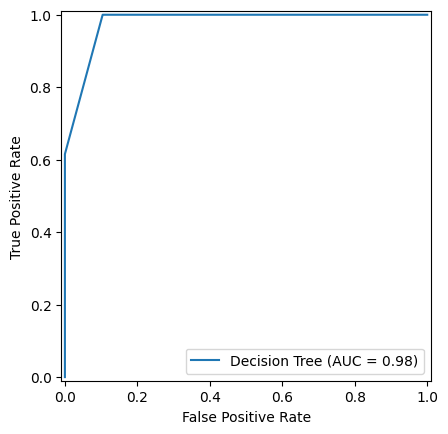

In [10]:
from sklearn.tree import DecisionTreeClassifier

clf3 = DecisionTreeClassifier(max_depth=3)
clf3.fit(np_X_norm, np_Y)

np_Y_pred = clf3.predict_proba(df_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   estimator_name='Decision Tree')
display.plot()
plt.show()

c:\Users\Fatima\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\Fatima\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


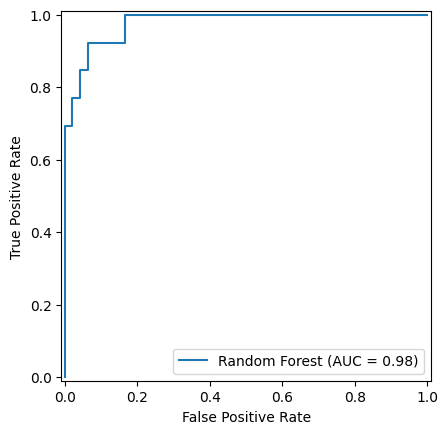

In [11]:
from sklearn.ensemble import RandomForestClassifier

clf4 = RandomForestClassifier(n_estimators=100, max_depth=3)
clf4.fit(np_X_norm, np_Y)

np_Y_pred = clf4.predict_proba(df_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   estimator_name='Random Forest')
display.plot()
plt.show()

**QUESTION 3**

Identify each used classifiers and specify the used parameters

Describe and explain the results obtained for each ROC curve. What is the relation between the AUC and the ROC curve ? According to the ROC curve, which model is the best if we want to maximize the sensitivity ? And if we want to maximize the specificity ? Compare those results with the AUC. 

**ANSWER**
1. the classifiers are , 
    - KNN , used paraameter : n_neighbors = 5
    - SVM, used parameters: C= 2.0, kernel = 'lineaar', probablity = True
    - Desicion Tree , used parameters: max_depth=3
    - random forest, used parameters: n_estimators= 100, max_depth = 3

2.  ROC plots sensitivity vs 1-specificuty as the decision threshold varies 
AUC is the area under the curve. 0.5= random, 1= perfect
meaning a random positive gets a higher score than a random negative 

To maximize sensitivity , model with highest true positive rate : decision tree (AUC = 0.98)

To min specificity , model with the lower false positive rate:
random forest (AUC = 0.99, which is the best one)


For a two-classes problem, a decision boundary is a hypersurface which splits the feature space between two sets (for each class). Then this surface is composed of all the equiprobability points in the feature space.

**TO DO 2.3**

Plot the decision boundary with df_X for each classifiers

<module 'matplotlib.pyplot' from 'c:\\Users\\Fatima\\AppData\\Local\\Programs\\Python\\Python310\\lib\\site-packages\\matplotlib\\pyplot.py'>

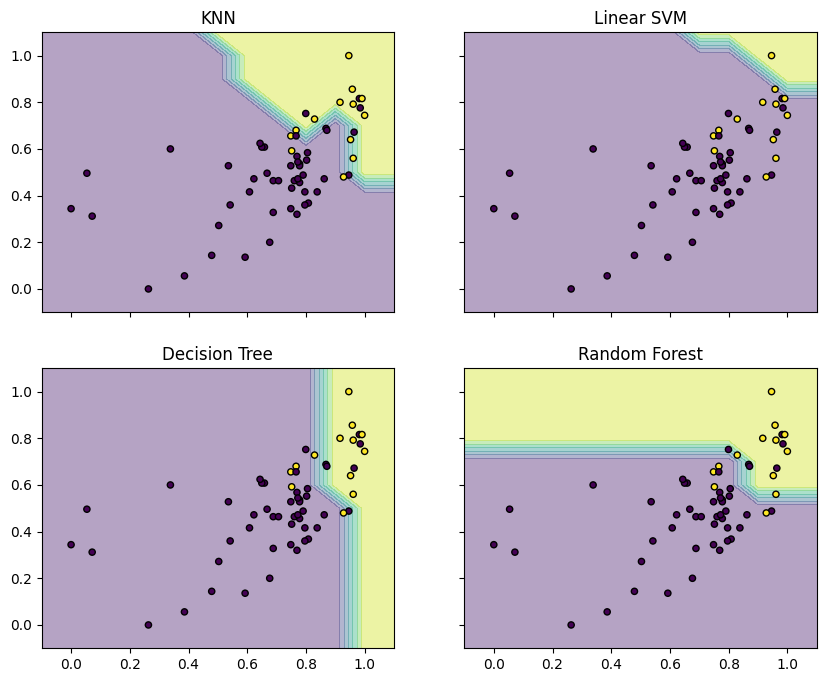

In [23]:
from itertools import product

x_min, x_max = np_X_norm[:, 0].min() - 0.1, np_X_norm[:, 0].max() + 0.1
y_min, y_max = np_X_norm[:, 1].min() - 0.1, np_X_norm[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

f, axarr = plt.subplots(2, 2, sharex='col', sharey='row', figsize=(10, 8))

for idx, clf, tt in zip(product([0, 1], [0, 1]),
                        [clf1, clf2, clf3, clf4],
                        ['KNN', 'Linear SVM', 'Decision Tree', 'Random Forest']):

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axarr[idx[0], idx[1]].contourf(xx, yy, Z, alpha=0.4)
    axarr[idx[0], idx[1]].scatter(np_X_norm[:, 0], np_X_norm[:, 1], c=np_Y,
                                  s=20, edgecolor='k')
    axarr[idx[0], idx[1]].set_title(tt)

plt

**QUESTION 4**

What is the main problem of the classification step with this dataset?

In your opinion, which classifier is better suited for this classification task? Justify your response

**Answer**

1. The main issue is the class imbalance, since the clasifier will tend to the majority class and perfom worse in the class that is less, especially that we have overlapping features. the below code shows that the number of developing countrues (21%) is much more than the developed ones.

2. Best classifier is the random forest or the decision tree, since both miss less developed countrues and cover them more than other classifiers, but since random forest has a best specificity it would be my best choice over the tree decision tree

In [13]:
np_Y.mean()

np.float64(0.21311475409836064)

## Checkpoint : 2
Call your teacher to validate the step 2

## STEP 3: Biases correction and model tuning

In this part, you will focus on improving the AUC scores of the four methods.

Firstable, you will weigh the classes to balance the classifier response. Then you will tune various hyperparameters.

**TO CODE 3.1**

Compute the percentage of "Developed" class in df_Y.

In [17]:
p_developed = np_Y.mean()*100
print(f'developed countries: :{p_developed:.2f}%')
print(f'developing countries: :{100-p_developed:.2f}%')

developed countries: :21.31%
developing countries: :78.69%


SVM, Decision Tree and Random Forest algorithms have a parameter named:

```
class_weight
```
Here is a extract from sklearn documentation:

**class_weight** dict, list of dict or “balanced”, default=None

Weights associated with classes in the form {class_label: weight}. If None, all classes are supposed to have weight one. For multi-output problems, a list of dicts can be provided in the same order as the columns of y.

The “balanced” mode uses the values of y to automatically adjust weights inversely proportional to class frequencies in the input data.


**QUESTION 5**

What would be the weight values for each class?

**Answer**

w= 1/(2* percentage of class)

w_developed= 2.346
w_developing = 0.635

In [18]:
w_developed= 1/(2*0.2131)
w_developing= 1/(2*0.7869)
print(w_developed, w_developing)

2.346316283435007 0.6354047528275512


**TO CODE 3.2**

Balance SVM, Decision Tree and Random Forest classifiers and plot the decision boundaries

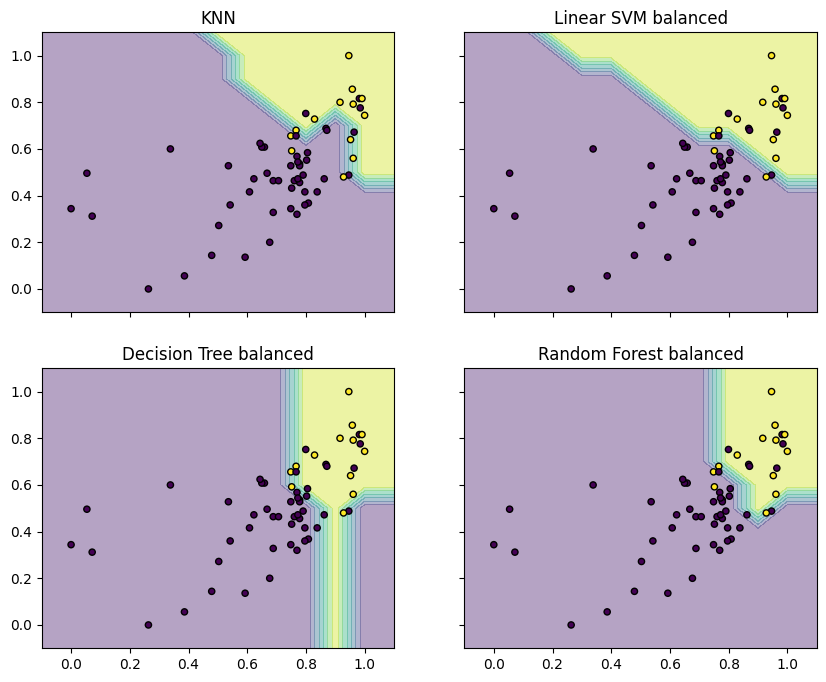

In [25]:
from itertools import product

x_min, x_max = np_X_norm[:, 0].min() - 0.1, np_X_norm[:, 0].max() + 0.1
y_min, y_max = np_X_norm[:, 1].min() - 0.1, np_X_norm[:, 1].max() + 0.1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

f, axarr = plt.subplots(2, 2, sharex='col', sharey='row', figsize=(10, 8))

for idx, clf, tt in zip(product([0, 1], [0, 1]),
                        [clf1, clf2b, clf3b, clf4b],
                        ['KNN', 'Linear SVM balanced',
                         'Decision Tree balanced', 'Random Forest balanced']):

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axarr[idx[0], idx[1]].contourf(xx, yy, Z, alpha=0.4)
    axarr[idx[0], idx[1]].scatter(np_X_norm[:, 0], np_X_norm[:, 1],
                                  c=np_Y, s=20, edgecolor='k')
    axarr[idx[0], idx[1]].set_title(tt)

plt.show()

**TO CODE 3.3**

Compute the new AUC scores

In [26]:
for name, clf in [('KNN', clf1), ('Balanced SVM', clf2),
                  ('Balanced Decision Tree', clf3), ('Balanced Random Forest', clf4)]:
    probabilities = clf.predict_proba(np_X_norm)[:, 1]
    auc = metrics.roc_auc_score(np_Y, probabilities)
    print(f'{name}: AUC = {auc:.3f}')

KNN: AUC = 0.929
Balanced SVM: AUC = 0.920
Balanced Decision Tree: AUC = 0.980
Balanced Random Forest: AUC = 0.978


**QUESTION 6**

Why did the AUC scores increase? How do you interpret it?

In your opinion, has the classe balance improved the classification?


**Answer**

1. The AUC doesnt really do a major increase , and mostly stays the same for some classes (with a few decimal differences), since it is threshold independent. what mainly changes is the sensitivuty and the specificity threshold at the default threshold at 0.5 . sinc ethe wieghts shift the decision threshold more towards the class that is less.

2. so balancing improve the detection of the minority class but not the quality measrued by the AUC

Let's focus on the SVM classifier.

Sklearn allows multiple kernels.

Here is an extract of the documentation:

**kernel** {‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’, ‘precomputed’}, default=’rbf’

Specifies the kernel type to be used in the algorithm. It must be one of ‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’, ‘precomputed’ or a callable. If none is given, ‘rbf’ will be used. If a callable is given it is used to pre-compute the kernel matrix from data matrices; that matrix should be an array of shape (n_samples, n_samples).


**TO CODE 3.4**

Test the gaussian and the polynomial kernels with balanced classes and plot the decision boundaries

Gaussian/RBF SVM: AUC = 0.915
Polynomial SVM: AUC = 0.915


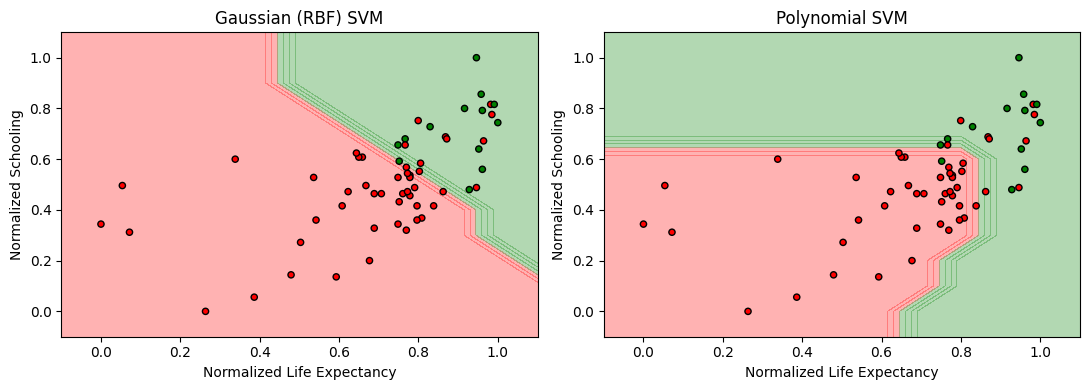

In [28]:
svm_rbf = SVC(C=2.0, kernel='rbf', probability=True, class_weight='balanced', random_state=42)
svm_poly = SVC(C=2.0, kernel='poly', probability=True, class_weight='balanced', random_state=42)
svm_rbf.fit(np_X_norm, np_Y)
svm_poly.fit(np_X_norm, np_Y)

for name, clf in [('Gaussian/RBF SVM', svm_rbf), ('Polynomial SVM', svm_poly)]:
    probabilities = clf.predict_proba(np_X_norm)[:, 1]
    print(f'{name}: AUC = {metrics.roc_auc_score(np_Y, probabilities):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, clf, title in zip(axes, [svm_rbf, svm_poly], ['Gaussian (RBF) SVM', 'Polynomial SVM']):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=matplotlib.colors.ListedColormap(['red', 'green']))
    ax.scatter(np_X_norm[:, 0], np_X_norm[:, 1], c=np_Y,
               cmap=matplotlib.colors.ListedColormap(['red', 'green']), s=20, edgecolor='k')
    ax.set_title(title)
    ax.set_xlabel('Normalized Life Expectancy')
    ax.set_ylabel('Normalized Schooling')
plt.tight_layout()
plt.show()

**QUESTION 7**

In your opinion, which is the best kernel for this dataset? Justify your response

**ANSWER**

the gaussian and the polynomial SVM achive the same AUC (0.915). On AUC alone , both have the sam eperformance. We notice that the decision boundary differ. Whereas the linear SVM shows a better performance AUC wise (0.92). So having a more complex kernel wasnt much benificial 

**BONUS**

Tune the parameters for Decision Tree and Random Forest algorithms and plot the decision boundaries

## Checkpoint : 3
Call your teacher to validate step 3

## STEP 4: An evaluation dataset

This part is to test the generalization of your models.

You trained several classifiers on two features extracted from the year 2000.

**TO CODE 4.1**

Apply your models on the year 2012

In [35]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
import numpy as np

df_train = df[df['Year'] == 2000]
X_train = df_train[['Life_expectancy', 'Schooling']]
y_train = df_train['Status'].map({'Developing': 0, 'Developed': 1})

df_2012 = df[df['Year'] == 2012]
X_2012 = df_2012[['Life_expectancy', 'Schooling']]
y_2012 = df_2012['Status'].map({'Developing': 0, 'Developed': 1})

train = X_train.copy()
train['Status'] = y_train
train = train.dropna()

test = X_2012.copy()
test['Status'] = y_2012
test = test.dropna()

X_train = train[['Life_expectancy', 'Schooling']]
y_train = train['Status'].astype(int)
X_2012 = test[['Life_expectancy', 'Schooling']]
y_2012 = test['Status'].astype(int)

scaler = MinMaxScaler()
X_train_norm = scaler.fit_transform(X_train)
X_2012_norm = scaler.transform(X_2012)

p_developed = np.mean(y_train == 1)

weights = {
    0: 0.5 / (1 - p_developed),
    1: 0.5 / p_developed
}

classifiers = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'KNN (balanced not supported)': KNeighborsClassifier(n_neighbors=5),

    'Linear SVM': SVC(C=2.0, kernel='linear', probability=True),
    'Linear SVM balanced': SVC(
        C=2.0, kernel='linear', probability=True,
        class_weight='balanced', random_state=0
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=3, random_state=0
    ),
    'Decision Tree balanced': DecisionTreeClassifier(
        max_depth=3, class_weight='balanced', random_state=0
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=3, random_state=0
    ),
    'Random Forest balanced': RandomForestClassifier(
        n_estimators=100, max_depth=3,
        class_weight='balanced', random_state=0
    )
}

print('AUC results on 2012 data:')

for name, clf in classifiers.items():
    clf.fit(X_train_norm, y_train)

    y_score = clf.predict_proba(X_2012_norm)[:, 1]
    auc = metrics.roc_auc_score(y_2012, y_score)

    print(name, ':', round(auc, 3))


AUC results on 2012 data:
KNN : 0.9
KNN (balanced not supported) : 0.9
Linear SVM : 0.952
Linear SVM balanced : 0.952
Decision Tree : 0.887
Decision Tree balanced : 0.873
Random Forest : 0.885
Random Forest balanced : 0.887


**QUESTION 8**

Are your models still relevant in the year 2012?

**ANSWER**

The models were trained on data from 2000 and evaluated on data from 2012. The Linear SVM had the best performance, with an AUC of 0.952, followed by KNN (0.900), Decision Tree (0.887), and Random Forest (0.885).

Class balancing did not change the Linear SVM's AUC. It slightly decreased the Decision Tree's performance.

Overall, the Linear SVM generalized best to the 2012 data, and balancing did not consistently improve model performance.

## Checkpoint : 4
Call your teacher to validate step 4. Congrats, you finished the second TP !